
# Лабораторная работа № 1. Задание 1
## Параллельный поиск точек множества Мандельброта

### Алгоритм и реализация

Программа на C с использованием `pthread` принимает два аргумента: `nthreads` - число рабочих потоков и `npoints` - требуемое количество точек. Результат сохраняется в `points.csv` (столбцы `x,y`).

Для параметра $c = a + bi$ проверяется последовательность:

$$
z_0 = 0, \qquad z_{k+1} = z_k^2 + c.
$$

Если в течение **1000 итераций** выполняется $|z_k|^2 > 4$, точка отвергается; иначе она **приближённо** считается принадлежащей множеству Мандельброта.

Поиск ведётся в области $a \in [-2, 1]$, $b \in [-1.5, 1.5]$. Начальная сетка - **101 × 101**. Если найдено недостаточно точек, число узлов по каждой оси увеличивается по формуле `grid_size = 2 * (grid_size - 1) + 1`.

На следующих уровнях пропускаются ранее проверенные узлы, у которых одновременно `i % 2 == 0` и `j % 2 == 0`. Поиск продолжается до получения ровно `npoints` записей.

**Пояснения к основным частям кода:**

- `is_mandelbrot(a, b)` - проверка одной точки, выполняется независимо в каждом потоке.
- `ThreadData` - параметры потока: диапазон столбцов `[start_i, end_i)`, размер сетки, число требуемых точек, указатели на общий счётчик, файл и мьютекс.
- `worker()` - перебор назначенных столбцов и всех строк; найденные точки записываются в CSV. `pthread_mutex_lock` / `pthread_mutex_unlock` защищают проверку общего счётчика, его увеличение и запись в общий файл. Сама проверка точки выполняется вне критической секции.
- `main()` - разбиение столбцов между потоками, запуск через `pthread_create`, ожидание через `pthread_join`, уточнение сетки при необходимости и освобождение ресурсов.

При тестировании для `npoints = 1000000` программа обработала сетки от **101 × 101** до **3201 × 3201** и во всех использованных запусках вывела `Найдено точек: 1000000 из 1000000`.

### Проверка корректности результатов

Дополнительно проверена корректность выходного CSV-файла для запусков с 2, 4 и 8 потоками. Во всех проверенных конфигурациях количество записанных точек совпадало с заданным, дубликаты координат отсутствовали, а все точки находились внутри выбранной области поиска. Для 1 000 000 точек файл содержал 1 000 001 строку с учётом заголовка.

### Аппаратная платформа и методика измерений

| Параметр | Значение |
|---|---|
| Процессор | AMD Ryzen 7 7735HS |
| Архитектура | x86_64 |
| Ядра / логические процессоры | 8 / 16 |
| Среда выполнения | Ubuntu 24.04, WSL2; Linux 6.18.54.1-microsoft-standard-WSL2 |
| Компилятор | GCC 13.3.0, флаги `-O2 -Wall -Wextra -pthread` |

Для **1 000 000 точек** сравнивались **1, 2, 4 и 8 потоков**. Время измерялось предоставленным `timer.h` (макрос `GET_TIME`, `gettimeofday()`) вокруг основного цикла поиска и уточнения сетки; подготовка данных и закрытие файла находились вне измеряемого интервала.

Для каждой конфигурации использовались **пять измерений**, по которым вычислялись **среднее** и **минимальное** время.

Ускорение вычислялось по средним временам:

$$
S_p = \frac{\overline{T}_1}{\overline{T}_p},
$$

где $\overline{T}_1$ - среднее время выполнения на одном потоке, а $\overline{T}_p$ - среднее время выполнения на $p$ потоках.

### Результаты производительности

| Потоков | Среднее время, с | Минимальное время, с | Ускорение |
|---:|---:|---:|---:|
| 1 | 4,3734 | 4,3305 | 1,00× |
| 2 | 3,5088 | 3,4814 | 1,25× |
| 4 | 3,2701 | 3,0389 | 1,34× |
| 8 | **2,3875** | **2,2709** | **1,83×** |

**Время выполнения в зависимости от количества потоков:**


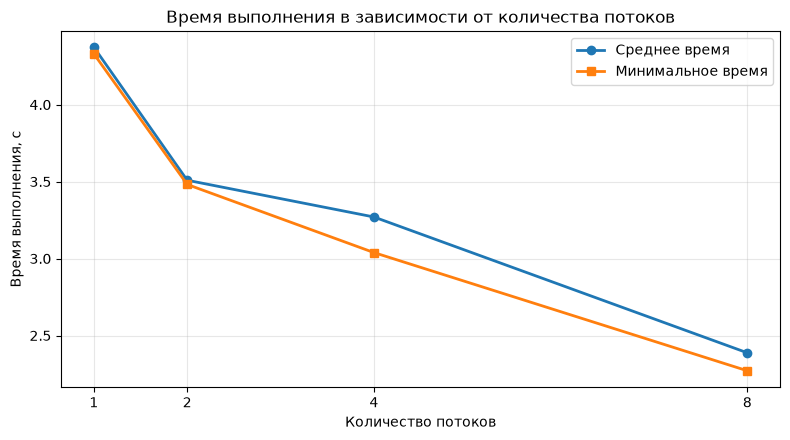

In [4]:
import matplotlib.pyplot as plt

threads = [1, 2, 4, 8]
mean_time = [4.3734, 3.5088, 3.2701, 2.3875]
min_time = [4.3305, 3.4814, 3.0389, 2.2709]

plt.figure(figsize=(8, 4.5))
plt.plot(threads, mean_time, marker="o", linewidth=2, label="Среднее время")
plt.plot(threads, min_time, marker="s", linewidth=2, label="Минимальное время")
plt.xticks(threads)
plt.xlabel("Количество потоков")
plt.ylabel("Время выполнения, с")
plt.title("Время выполнения в зависимости от количества потоков")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Ускорение относительно одного потока:**

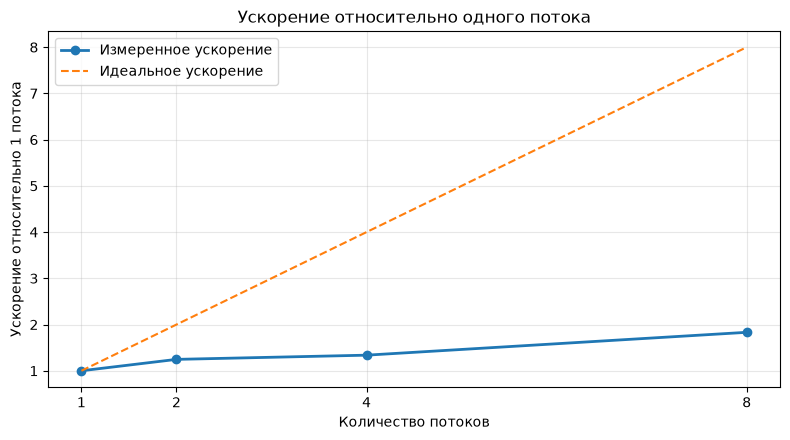

In [5]:
import matplotlib.pyplot as plt

threads = [1, 2, 4, 8]
mean_time = [4.3734, 3.5088, 3.2701, 2.3875]
speedup = [mean_time[0] / t for t in mean_time]
ideal_speedup = threads

plt.figure(figsize=(8, 4.5))
plt.plot(threads, speedup, marker="o", linewidth=2, label="Измеренное ускорение")
plt.plot(threads, ideal_speedup, linestyle="--", label="Идеальное ускорение")
plt.xticks(threads)
plt.xlabel("Количество потоков")
plt.ylabel("Ускорение относительно 1 потока")
plt.title("Ускорение относительно одного потока")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Вывод

Параллельная программа корректно находит и сохраняет заданное количество точек. На исследованной платформе переход от 1 к 8 потокам сократил среднее время поиска миллиона точек с **4,37 до 2,39 с**, обеспечив ускорение **1,83 раза**. Ускорение при увеличении количества потоков оказалось нелинейным. Это может быть связано с несколькими факторами: необходимостью синхронизации потоков при записи найденных точек в общий CSV-файл, накладными расходами на создание и завершение потоков, а также неравномерной вычислительной нагрузкой. Хотя столбцы сетки распределяются между потоками равномерно, количество итераций, необходимых для проверки разных точек, может существенно отличаться. Поэтому отдельные потоки могут завершать вычисления раньше других, что снижает эффективность параллельного выполнения.